In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from skimage import measure, transform

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    recall_score,
    precision_score,
)

In [2]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.model_selection import GridSearchCV

In [3]:
from pathlib import Path

In [4]:
DATA_DIR = Path("./data/original")

In [5]:
images = []  # list of 2D numpy arrays (grayscale)
labels = []  # class name taken from the file name, e.g. "watch" from "watch-2.gif"

for path in sorted(DATA_DIR.glob("*.gif")):
    images.append(np.asarray(Image.open(path).convert("L")))
    labels.append(path.stem.rsplit("-", 1)[0])

print(f"Loaded {len(images)} images, {len(set(labels))} classes")
print("Example shape:", images[0].shape)

Loaded 1400 images, 70 classes
Example shape: (439, 357)


In [6]:
def get_mask(img):
    """Binary mask: True = object. Objects are bright on a dark background."""
    mask = img > 127
    return mask

In [7]:
raw_masks = [get_mask(im) for im in images]

In [8]:
def largest_region(mask):
    return max(measure.regionprops(measure.label(mask)), key=lambda r: r.area)

In [9]:
def compactness(r):
    return 4.0 * np.pi * r.area / (r.perimeter**2)


def extract_features(mask):
    r = largest_region(mask)
    minr, minc, maxr, maxc = r.bbox
    return [
        r.area,  # area
        r.perimeter,  # perimeter
        r.equivalent_diameter_area,  # diameter of circle with the same area
        maxc - minc,  # bounding box width
        maxr - minr,  # bounding box height
        compactness(r),
    ]


X = np.array([extract_features(m) for m in raw_masks])
print("X shape:", X.shape)

X shape: (1400, 6)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, labels, test_size=0.2, stratify=labels, random_state=42
)

In [11]:
pipeline = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid = {
    "kneighborsclassifier__n_neighbors": [1, 3, 5, 7, 9, 15],
    "kneighborsclassifier__weights": ["uniform", "distance"],
}

search = GridSearchCV(pipeline, param_grid, cv=cv, n_jobs=-1)
search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'kneighborsclassifier__n_neighbors': [1, 3, ...], 'kneighborsclassifier__weights': ['uniform', 'distance']}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added."

In [13]:
print(search.best_params_, search.best_score_)
print("test:", search.score(X_test, y_test))

{'kneighborsclassifier__n_neighbors': 1, 'kneighborsclassifier__weights': 'uniform'} 0.6830357142857142
test: 0.7285714285714285


In [14]:
model = search.best_estimator_

In [15]:
scores = cross_val_score(model, X_train, y_train, cv=cv)
scores

array([0.64285714, 0.69196429, 0.68303571, 0.70982143, 0.6875    ])

In [16]:
predicted_label = model.predict(X_test[0].reshape(1, -1))[0]
real_label = y_test[0]

print(f"Predicted label: {predicted_label}")
print(f"Real label: {real_label}")

Predicted label: chicken
Real label: chicken


In [17]:
def print_metrics(y_true, y_pred):
    print(f"accuracy:  {accuracy_score(y_true, y_pred):.3f}")
    print(
        f"precision: {precision_score(y_true, y_pred, average='macro', zero_division=0):.3f}"
    )
    print(
        f"recall:    {recall_score(y_true, y_pred, average='macro', zero_division=0):.3f}"
    )


y_pred = model.predict(X_test)
print_metrics(y_test, y_pred)

accuracy:  0.729
precision: 0.729
recall:    0.729


        device3 <-> device9          9   (3 / 6)
        device0 <-> device5          8   (4 / 4)
   personal_car <-> shoe             7   (1 / 6)
          crown <-> dog              7   (5 / 2)
          camel <-> chicken          7   (3 / 4)
         pencil <-> watch            7   (4 / 3)
         beetle <-> fly              6   (4 / 2)
         guitar <-> turtle           6   (3 / 3)
 cellular_phone <-> personal_car     4   (2 / 2)
        lizzard <-> spring           4   (3 / 1)
        device2 <-> device5          4   (2 / 2)
            fly <-> octopus          4   (2 / 2)
        device0 <-> device1          3   (1 / 2)
      butterfly <-> device1          3   (2 / 1)
           bird <-> deer             3   (2 / 1)


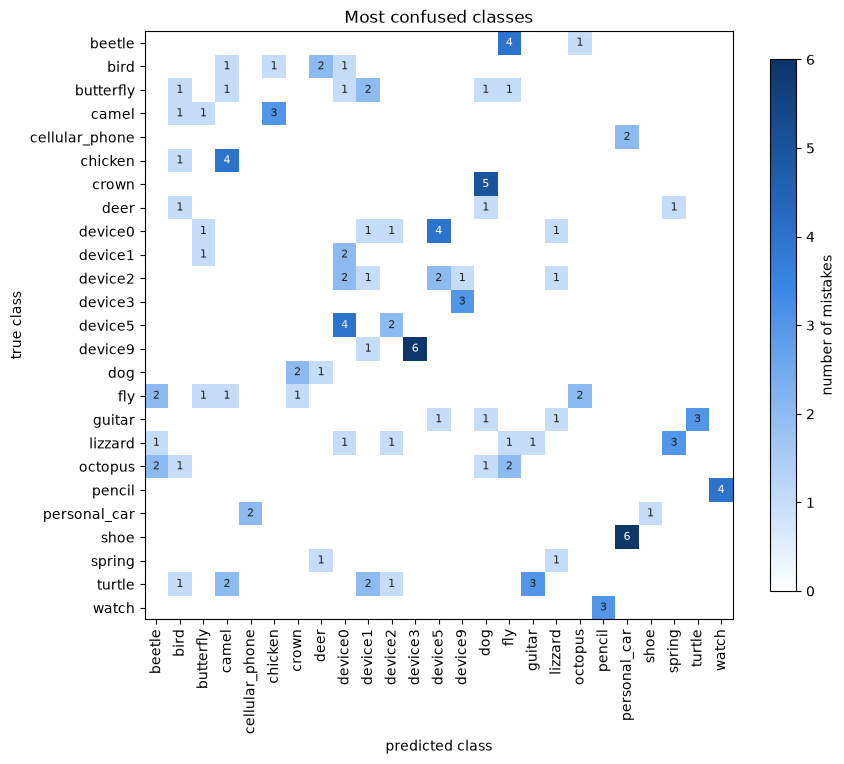

In [18]:
from matplotlib.colors import LinearSegmentedColormap
from sklearn.model_selection import cross_val_predict

y_pred_cv = cross_val_predict(model, X_train, y_train, cv=cv)

classes = np.unique(y_train)
errors = confusion_matrix(y_train, y_pred_cv, labels=classes)
np.fill_diagonal(errors, 0)

cmap = LinearSegmentedColormap.from_list(
    "errors",
    [
        "#ffffff",
        "#cde2fb",
        "#9ec5f4",
        "#6da7ec",
        "#3987e5",
        "#256abf",
        "#184f95",
        "#0d366b",
    ],
)

pair_errors = errors + errors.T
i, j = np.triu_indices(len(classes), k=1)
top = np.argsort(pair_errors[i, j])[::-1][:15]
for k in top:
    a, b = i[k], j[k]
    print(
        f"{classes[a]:>15} <-> {classes[b]:<15} {pair_errors[a, b]:2d}   ({errors[a, b]} / {errors[b, a]})"
    )

idx = np.unique(np.concatenate([i[top], j[top]]))
sub = errors[np.ix_(idx, idx)]

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(sub, cmap=cmap)
ax.set_xticks(range(len(idx)), classes[idx], rotation=90)
ax.set_yticks(range(len(idx)), classes[idx])
for r, c in zip(*np.nonzero(sub)):
    ax.text(
        c,
        r,
        sub[r, c],
        ha="center",
        va="center",
        fontsize=8,
        color="white" if sub[r, c] > sub.max() / 2 else "#1f1f1f",
    )
ax.set_xlabel("predicted class")
ax.set_ylabel("true class")
ax.set_title("Most confused classes")
fig.colorbar(im, ax=ax, shrink=0.8, label="number of mistakes")
fig.tight_layout()
plt.show()

Central mass, normalization.

In [19]:
def center_and_normalize(mask, max_size=128, margin=0.1):
    r = largest_region(mask)
    cy, cx = r.centroid_local
    h, w = r.image.shape
    half = int(np.ceil(max(cy, h - cy, cx, w - cx) * (1 + margin)))
    padded = np.pad(r.image, half + 1)
    cy, cx = int(round(cy)) + half + 1, int(round(cx)) + half + 1
    crop = padded[cy - half : cy + half, cx - half : cx + half]
    if crop.shape[0] > max_size:  # shrink only, never upscale
        crop = transform.resize(crop.astype(float), (max_size, max_size), order=1) > 0.5
    return crop

In [20]:
norm_masks = [center_and_normalize(m) for m in raw_masks]

In [21]:
def get_contour(img):
    # pad so the contour closes even if the object touches the border
    return max(measure.find_contours(np.pad(img, 1), 0.5), key=len) - 1

In [22]:
def asymmetry(img):
    # mirror the object over its principal axes, count pixels that miss it
    pts = np.argwhere(img).astype(float)
    c = pts.mean(axis=0)
    pts -= c
    _, axes = np.linalg.eigh(np.cov(pts.T))
    best = 1.0
    for n in axes.T:
        refl = np.round(pts - 2 * np.outer(pts @ n, n) + c).astype(int)
        ok = ((refl >= 0) & (refl < img.shape)).all(axis=1)
        best = min(best, 1 - img[refl[ok, 0], refl[ok, 1]].sum() / len(pts))
    return best


def complex_features(mask):
    r = largest_region(mask)
    radii = np.linalg.norm(get_contour(r.image) - r.centroid_local, axis=1)
    _, (w, h), _ = cv2.minAreaRect(r.coords[:, ::-1].astype(np.float32))

    return [
        r.area / ((w + 1) * (h + 1)),  # rectangularity
        min(w, h) / max(w, h),  # squareness
        radii.min() / radii.max(),
        radii.mean() / radii.max(),
        radii.std() / radii.mean(),
        asymmetry(r.image),
        r.solidity,
        r.eccentricity,
    ]

Shape signature: distance from the centroid along the contour.

In [23]:
def signature(mask, n=64):
    # distance from the centroid along the contour, n equally spaced points
    r = largest_region(mask)
    contour = get_contour(r.image)
    s = np.r_[0, np.cumsum(np.linalg.norm(np.diff(contour, axis=0), axis=1))]
    t = np.linspace(0, s[-1], n, endpoint=False)
    pts = np.c_[np.interp(t, s, contour[:, 0]), np.interp(t, s, contour[:, 1])]
    d = np.linalg.norm(pts - r.centroid_local, axis=1)
    d /= d.mean()  # scale invariance
    return np.roll(d, -d.argmax())  # start at the farthest point

In [24]:
extractors = {
    "simple": extract_features,
    "complex": complex_features,
    "signature": signature,
}
masks = {"raw": raw_masks, "norm": norm_masks}

F = {
    (prep, name): np.array([f(m) for m in ms])
    for prep, ms in masks.items()
    for name, f in extractors.items()
}

Comparison: kNN, raw vs centered + normalized masks.

In [25]:
y = np.array(labels)
idx_train, idx_test = train_test_split(
    np.arange(len(y)), test_size=0.2, stratify=y, random_state=42
)

feature_sets = {
    "simple": ["simple"],
    "complex": ["complex"],
    "signature": ["signature"],
    "simple+complex": ["simple", "complex"],
    "simple+signature": ["simple", "signature"],
    "all": ["simple", "complex", "signature"],
}


def get_X(prep, names):
    return np.hstack([F[prep, n] for n in names])


results = {}
for prep in ["raw", "norm"]:
    for name, parts in feature_sets.items():
        gs = GridSearchCV(pipeline, param_grid, cv=cv, n_jobs=-1)
        gs.fit(get_X(prep, parts)[idx_train], y[idx_train])
        results[prep, name] = gs

print(f"{'':18s}{'raw':>15s}{'norm':>15s}")
for name in feature_sets:
    row = ""
    for prep in ["raw", "norm"]:
        gs = results[prep, name]
        std = gs.cv_results_["std_test_score"][gs.best_index_]
        row += f"{gs.best_score_:8.3f} ±{std:.3f}"
    print(f"{name:18s}{row}")

                              raw           norm
simple               0.683 ±0.022   0.670 ±0.013
complex              0.818 ±0.019   0.816 ±0.016
signature            0.806 ±0.006   0.823 ±0.020
simple+complex       0.865 ±0.016   0.849 ±0.022
simple+signature     0.841 ±0.016   0.846 ±0.016
all                  0.856 ±0.015   0.877 ±0.011


In [26]:
best_prep, best_name = max(results, key=lambda k: results[k].best_score_)
X_best = get_X(best_prep, feature_sets[best_name])
y_pred_best = results[best_prep, best_name].predict(X_best[idx_test])

print(f"best: {best_prep} / {best_name}")
print_metrics(y[idx_test], y_pred_best)

best: norm / all
accuracy:  0.818
precision: 0.829
recall:    0.818
